# Evolución del precio del alquiler de vivienda

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"                       # carpeta en research/temas/
GRAFICA_ID = "evolucion-precios-alquiler"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Evolución del precio del alquiler de vivienda"  # `titulo` de la gráfica en config.json
DESDE = 1976                            # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"                 # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Índice"                       # se completa con el año base en la transformación
CSV_FORMATO = "es"                      # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2                       # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 100                        # línea horizontal de referencia en el valor base del índice
DIR_SALIDA = None                       # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cuánto ha subido el precio del alquiler de vivienda, en euros corrientes (o en la moneda de cada país), según el componente de alquiler del índice de precios de consumo (IPC). Se expresa como índice con 100 en el primer año en que hay datos de todas las áreas y de todas las comunidades autónomas, el mismo en las dos vistas; el año base figura en la unidad.

**Cómo se lee.** Un valor de 150 significa que el alquiler es un 50 % más caro que en el año base. La gráfica compara **evoluciones**, no niveles: que dos áreas estén en el mismo valor no significa que el alquiler cueste lo mismo en ellas.

**Limitaciones.**
- Es un índice **nominal**: incluye la inflación general, que no es igual en todas las áreas. La media de la OCDE agrega países con inflaciones muy distintas, algunas muy altas en ciertos periodos, y eso se refleja en su evolución. Para comparar el alquiler con el resto de precios está la gráfica `evolucion-precios-alquiler-real` (solo en notebook).
- El componente de alquiler del IPC mide la renta que pagan **todos los contratos vigentes**, no solo los que se firman cada año. Por eso sube más despacio que los precios de los contratos nuevos o de los anuncios.
- La UE-27 usa el índice armonizado de Eurostat (IPCA) y el resto de áreas el IPC nacional que publica la OCDE. Sus métodos son parecidos pero no idénticos.

**Vista por comunidades.** El selector «Por comunidad» de la web muestra la evolución del mismo componente de alquiler del IPC en cada comunidad y ciudad autónoma, con el total de España de la misma tabla del INE y sin las referencias internacionales. Usa el mismo año base que la vista España: compara cuánto ha subido el alquiler en cada comunidad desde ese año, no cuánto cuesta.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** índice de alquileres (`RPI`) de los *Analytical house price indicators* de la OCDE, que es el componente de alquiler del IPC nacional.
- **UE-27:** IPCA anual de Eurostat (`prc_hicp_ainr`, clasificación ECOICOP v2), subclase 04.1 «alquileres efectivos de la vivienda».
- **Vista por comunidades:** INE, IPC, tabla 76137 (índices por comunidades autónomas de subgrupos ECOICOP v2), subgrupo «Alquiler de vivienda»: una serie mensual por comunidad y la del total nacional, enlazadas por el INE desde 2002.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, eurostat, ine, oecd
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

AREAS_OCDE = {"ESP": "espana", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}
DF_ALQUILER = "OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES,1.0"
HICP = "prc_hicp_ainr"
# INE, IPC, tabla 76137: subgrupo «Alquiler de vivienda», índice mensual del total nacional y de cada comunidad
IPC_ALQUILER_CCAA = {
    "IPC290887": "espana", "IPC294988": "ES-AN", "IPC295172": "ES-AR", "IPC295356": "ES-AS", "IPC295540": "ES-IB",
    "IPC295724": "ES-CN", "IPC295908": "ES-CB", "IPC296092": "ES-CL", "IPC296276": "ES-CM", "IPC296460": "ES-CT",
    "IPC296644": "ES-VC", "IPC296828": "ES-EX", "IPC297012": "ES-GA", "IPC297196": "ES-MD", "IPC297380": "ES-MC",
    "IPC297564": "ES-NC", "IPC297748": "ES-PV", "IPC297932": "ES-RI", "IPC298116": "ES-CE", "IPC294804": "ES-ML",
}


def descargar():
    """Devuelve (DataFrame `serie, periodo, valor` con los índices tal como los publica cada fuente, fuentes)."""
    alq_ocde, f_ocde = oecd.get(DF_ALQUILER, "{AREA}.A.RPI.IX", areas=AREAS_OCDE, desde=DESDE)
    alq_ue, f_ue = eurostat.get(
        HICP, {"freq": "A", "unit": "INX_A_AVG", "coicop18": "CP041"}, geos={"EU27_2020": "ue27"}, desde=DESDE
    )
    return pd.concat([alq_ocde, alq_ue], ignore_index=True), [*f_ocde, *f_ue]


def descargar_ccaa():
    """Índice del alquiler del IPC por comunidad y del total nacional, en media anual (solo años completos)."""
    return ine.get(IPC_ALQUILER_CCAA, agregacion="media", desde=DESDE)


publicado, fuentes = descargar()
publicado_ccaa, fuentes_ccaa = descargar_ccaa()
print(publicado.dropna().groupby("serie")["periodo"].agg(["min", "max"]).to_dict("index"))

{'canada': {'min': 1976, 'max': 2025}, 'eeuu': {'min': 1976, 'max': 2024}, 'espana': {'min': 1976, 'max': 2025}, 'ocde': {'min': 1976, 'max': 2025}, 'ue27': {'min': 2000, 'max': 2025}}


## 3. Transformación

Cada fuente publica su índice con una base distinta. Se rebasan todos, también los de las comunidades autónomas, al primer año en que todas las series de las dos vistas tienen dato, para que partan del mismo punto: índice = valor / valor en el año base × 100.

In [ ]:
ancho = publicado.pivot(index="periodo", columns="serie", values="valor")
ancho_ccaa = publicado_ccaa.pivot(index="periodo", columns="serie", values="valor")

# Año base: primer año con dato en todas las series que tienen alguno (skill investigar-tema), de las dos
# vistas, para que España y las comunidades tengan el 100 en el mismo año
con_datos = [s for s in ancho.columns if ancho[s].notna().any()]
completos = ancho[con_datos].notna().all(axis=1)
completos_ccaa = ancho_ccaa.notna().all(axis=1)
comunes = completos[completos].index.intersection(completos_ccaa[completos_ccaa].index)
BASE = int(comunes.min())
UNIDAD = f"Índice, {BASE} = 100 (componente de alquiler del IPC, nominal)"

indice = ancho / ancho.loc[BASE] * 100
df = indice.reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]

NOTAS = [
    f"Índice nominal del componente de alquiler de vivienda del índice de precios de consumo, con {BASE} = 100, el primer año con datos de todas las áreas y de todas las comunidades autónomas (el mismo año base que la vista por comunidades). Incluye la inflación general de cada área.",
    "España, OCDE, EE. UU. y Canadá: índice de alquileres (RPI) de los Analytical house price indicators de la OCDE, que es el componente de alquiler del IPC nacional enlazado por la OCDE entre cambios de base. En España, el IPC es el del INE.",
    "UE-27: IPCA anual de Eurostat (prc_hicp_ainr, ECOICOP v2), subclase 04.1 «alquileres efectivos de la vivienda». Agregado de composición actual (EU27_2020). El IPCA y los IPC nacionales usan métodos parecidos pero no idénticos.",
    "OCDE: la media agrega países con inflaciones muy distintas, algunas muy altas en ciertos periodos, y en términos nominales eso se refleja en su evolución. La comparación con el resto de precios está en la gráfica evolucion-precios-alquiler-real.",
    "El componente de alquiler del IPC mide la renta de todos los contratos vigentes, no solo la de los contratos nuevos, por lo que sube más despacio que los precios de los contratos que se firman cada año.",
]

# Series que terminan antes que las demás
ultimo_global = max(indice[s].last_valid_index() for s in con_datos)
for s in con_datos:
    ult = indice[s].last_valid_index()
    if ult < ultimo_global:
        NOTAS.append(f"{s}: el último año con dato es {ult} porque la fuente aún no ha publicado el dato anual de {ult + 1}.")

# Vista por comunidades: el índice del INE, con el mismo año base que la vista España
indice_ccaa = ancho_ccaa / ancho_ccaa.loc[BASE] * 100
df_ccaa = indice_ccaa.reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]
NOTAS_CCAA = [
    f"Índice nominal del componente de alquiler de vivienda del IPC del INE en cada comunidad y ciudad autónoma, con {BASE} = 100, el mismo año base que la vista España. Compara cuánto ha subido el alquiler en cada una desde ese año, no cuánto cuesta.",
    "INE, IPC, tabla 76137 (índices por comunidades autónomas de subgrupos ECOICOP v2), subgrupo «Alquiler de vivienda»: series mensuales enlazadas por el INE desde 2002; se usa la media de los doce meses de cada año. España es el total nacional de la misma tabla, que puede diferir ligeramente de la serie de la OCDE de la vista España.",
    "El componente de alquiler del IPC mide la renta de todos los contratos vigentes, no solo la de los contratos nuevos.",
]
vista_ccaa = construir_vista_ccaa(df_ccaa, fuentes_ccaa, unidad=UNIDAD, notas=NOTAS_CCAA, desde=DESDE, referencia=REFERENCIA)
ultimo_ccaa = {k: round(v[-1], 1) for k, v in vista_ccaa["series"].items() if v[-1] is not None}
print(f"base {BASE}; {vista_ccaa['labels'][-1]}:", ultimo_ccaa)

base 2002; 2025: {'espana': 152.5, 'ES-AN': 153.4, 'ES-AR': 157.1, 'ES-AS': 144.9, 'ES-CB': 151.8, 'ES-CE': 147.3, 'ES-CL': 140.0, 'ES-CM': 142.1, 'ES-CN': 140.8, 'ES-CT': 160.0, 'ES-EX': 135.6, 'ES-GA': 148.6, 'ES-IB': 159.4, 'ES-MC': 136.7, 'ES-MD': 154.8, 'ES-ML': 145.7, 'ES-NC': 133.0, 'ES-PV': 151.2, 'ES-RI': 131.6, 'ES-VC': 152.3}


## 4. Visualización

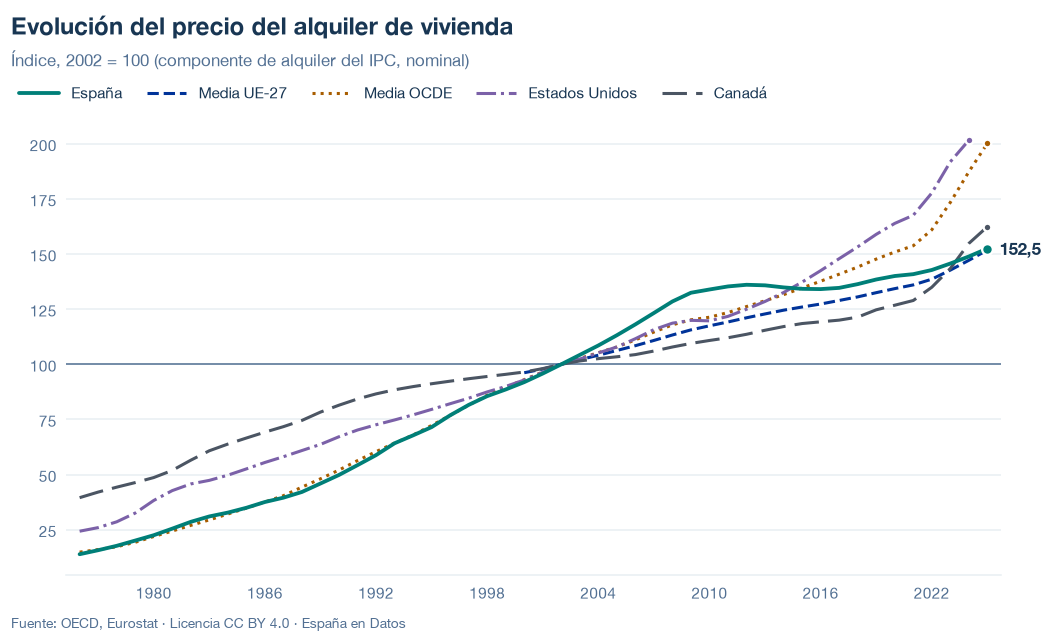

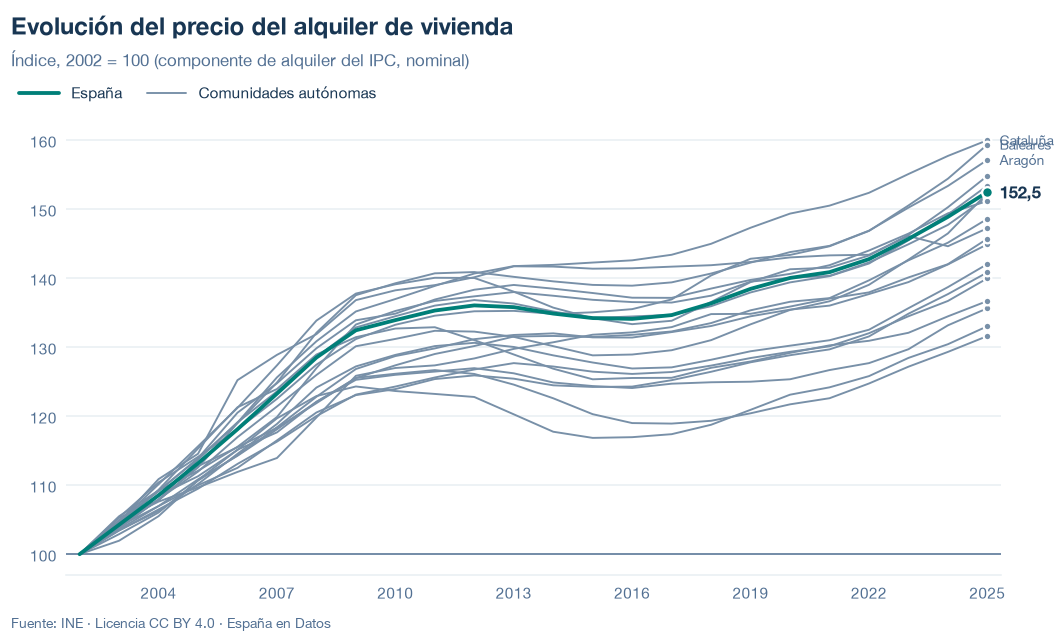

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/evolucion-precios-alquiler.json y data/evolucion-precios-alquiler.csv


## 6. Fuentes, notas y licencia

**Fuentes:**
- OCDE, *Analytical house price indicators* (`OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES`), medida `RPI` (alquileres).
- Eurostat, IPCA anual (`prc_hicp_ainr`), subclase 04.1.
- INE, IPC, tabla 76137 (índices por comunidades autónomas de subgrupos ECOICOP v2), subgrupo «Alquiler de vivienda» (vista por comunidades).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Notas:** están en `notas` del JSON e incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.